In [1]:
import os
import glob
import time
import gc
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from datetime import timedelta
from PIL import Image
from ultralytics import YOLO
import torch
import rasterio
from rasterio.transform import from_origin
from rasterio.windows import Window
from shapely.geometry import Polygon
from shapely.ops import unary_union
from sklearn.cluster import DBSCAN
from pyproj import Transformer
import cv2
import pandas as pd
import numpy as np
import json
from shapely.geometry import Polygon
from sklearn.cluster import DBSCAN

# ======================== Drawing ========================
def draw_annotations_on_image(full_image_array, slices, object_infos, output_path):
    """
    Overlays bounding boxes, masks, and lat/lon centers with:
    - Transparent masks (alpha=0.3)
    - Class/conf labels
    - Red dot + lat/lon text
    - JPEG output
    """
    import cv2
    import numpy as np
    import json
    from rasterio.transform import rowcol

    # Convert rasterio (C,H,W) to OpenCV (H,W,C)
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = np.clip((img / img.max()) * 255, 0, 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    overlay = img.copy()

    # Offset lookup
    slice_offsets = {tuple(slice_data["offset_xy"]): slice_data for slice_data in slices}

    for obj in object_infos:
        tile_name = obj['tile_name']
        offset_xy = (int(obj['global_x'] - obj['x_center']), int(obj['global_y'] - obj['y_center']))

        # Bounding box
        x1_global = int(obj['bbox_x1'] + offset_xy[0])
        y1_global = int(obj['bbox_y1'] + offset_xy[1])
        x2_global = int(obj['bbox_x2'] + offset_xy[0])
        y2_global = int(obj['bbox_y2'] + offset_xy[1])

        conf = obj['confidence']
        cls = obj['class']
        label = f"Cls:{cls} ({conf:.2f})"

        # Draw bounding box
        cv2.rectangle(overlay, (x1_global, y1_global), (x2_global, y2_global), (0, 255, 0), 3)

        # Label text
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 2.5
        thickness = 5
        text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
        text_origin = (x1_global, max(y1_global - 10, text_size[1]))
        cv2.putText(overlay, label, text_origin, font, font_scale, (0, 0, 0), thickness + 2)
        cv2.putText(overlay, label, text_origin, font, font_scale, (255, 255, 255), thickness)

        # Mask overlay
        try:
            mask_points = np.array(json.loads(obj['mask_points']), dtype=np.int32)
            mask_points_global = mask_points + np.array([offset_xy[0], offset_xy[1]])

            if len(mask_points_global) >= 3:
                mask_img = np.zeros_like(img)
                cv2.fillPoly(mask_img, [mask_points_global], (0, 0, 255))
                cv2.polylines(mask_img, [mask_points_global], isClosed=True, color=(0, 0, 255), thickness=2)
                overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.7, 0)
        except:
            pass

        # Lat/Lon center overlay
        try:
            lat = float(obj['latitude'])
            lon = float(obj['longitude'])

            # Use reverse transform to get row,col (y,x)
            for slice_data in slices:
                transform = slice_data['transform']
                try:
                    row, col = rowcol(transform, lon, lat)
                    pixel_x = col + slice_data["offset_xy"][0]
                    pixel_y = row + slice_data["offset_xy"][1]
                    break
                except:
                    continue

            # Draw center point
            cv2.circle(overlay, (int(pixel_x), int(pixel_y)), 8, (0, 0, 255), -1)

            # Add lat/lon text
            ll_label = f"({lat:.5f}, {lon:.5f})"
            cv2.putText(overlay, (int(pixel_x + 10), int(pixel_y - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 3)
            cv2.putText(overlay, (int(pixel_x + 10), int(pixel_y - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
        except:
            continue

    # Save as JPEG
    output_path_jpg = output_path.replace(".png", ".jpg")
    cv2.imwrite(output_path_jpg, overlay)
    print(f"📸 Annotated image saved to: {output_path_jpg}")

# ======================== Sliding ========================
from rasterio.windows import Window
from rasterio.transform import from_origin

def slide_geotiff(geotiff_path, window_size, stride):
    """
    Splits a GeoTIFF into window_size×window_size tiles with given stride,
    **and** adds extra overlapping tiles on the right/bottom so that no pixel is left out.
    """
    tiles = []
    with rasterio.open(geotiff_path) as src:
        height, width = src.height, src.width

        # 1) Compute all x-starts
        if width <= window_size:
            x_starts = [0]
        else:
            x_starts = list(range(0, width - window_size + 1, stride))
            # leftover on right?
            if x_starts[-1] + window_size < width:
                x_starts.append(width - window_size)

        # 2) Compute all y-starts
        if height <= window_size:
            y_starts = [0]
        else:
            y_starts = list(range(0, height - window_size + 1, stride))
            # leftover on bottom?
            if y_starts[-1] + window_size < height:
                y_starts.append(height - window_size)

        # 3) Build tiles for every (x,y) pair
        for y in y_starts:
            for x in x_starts:
                window = Window(x, y, window_size, window_size)
                slice_img = src.read(window=window)
                new_transform = from_origin(
                    src.transform.c + x * src.transform.a,
                    src.transform.f + y * src.transform.e,
                    src.transform.a,
                    -src.transform.e
                )
                tiles.append({
                    "img_array": slice_img,
                    "transform": new_transform,
                    "crs": src.crs,
                    "position": (y, x),
                    "offset_xy": (x, y)
                })

    return tiles


# ======================== Per-Tile Suppression ========================
from torchvision.ops import nms
def maximum_likelihood_suppression(results, conf_threshold=0.7, iou_threshold=0.5):
    if results.masks is None or results.boxes is None or results.boxes.data is None:
        return results
    boxes = results.boxes.xyxy
    scores = results.boxes.conf
    keep = scores >= conf_threshold
    if keep.sum() == 0:
        results.boxes.data = results.boxes.data[[]]
        if results.masks and results.masks.data is not None:
            results.masks.data = results.masks.data[[]]
        return results
    keep_indices = nms(boxes[keep], scores[keep], iou_threshold)
    indices_to_keep = torch.nonzero(keep).squeeze(1)[keep_indices]
    results.boxes.data = results.boxes.data[indices_to_keep]
    if results.masks and results.masks.data is not None:
        results.masks.data = results.masks.data[indices_to_keep]
    return results

# ======================== Per-Tile Extraction ========================
def overlay_segmentation_on_array(results, transform, img_shape, tif_image, offset_xy):
    object_data = []
    masks_out = []

    if results.masks is None or results.boxes is None or results.boxes.data is None:
        return object_data, masks_out

    for idx, (mask, box, cls, conf) in enumerate(zip(
        results.masks.xy, results.boxes.xyxy, results.boxes.cls, results.boxes.conf)):

        cls = int(cls.item())
        conf = float(conf.item())
        x1, y1, x2, y2 = map(float, box.tolist())

        mask_pixel_coords = np.array(mask.tolist(), dtype=np.float32)
        mask_gis_coords = []
        for px, py in mask_pixel_coords:
            try:
                lon, lat = rasterio.transform.xy(transform, py, px)
                mask_gis_coords.append([lon, lat])
            except:
                continue

        pixel_count = len(mask_pixel_coords)
        area = pixel_count * (transform.a * abs(transform.e))
        local_cx = (x1 + x2) / 2
        local_cy = (y1 + y2) / 2
        global_x = offset_xy[0] + local_cx
        global_y = offset_xy[1] + local_cy
        lon_center, lat_center = rasterio.transform.xy(transform, local_cy, local_cx)
        lon_x1, lat_y1 = rasterio.transform.xy(transform, y1, x1)
        lon_x2, lat_y2 = rasterio.transform.xy(transform, y2, x2)
        bbox_width_geo = abs(lon_x2 - lon_x1)
        bbox_height_geo = abs(lat_y2 - lat_y1)

        object_data.append({
            "latitude": lat_center,
            "longitude": lon_center,
            "bbox_lat_y1": lat_y1,
            "bbox_lon_x1": lon_x1,
            "bbox_lat_y2": lat_y2,
            "bbox_lon_x2": lon_x2,
            "bbox_width_geo": bbox_width_geo,
            "bbox_height_geo": bbox_height_geo,
            "global_x": global_x,
            "global_y": global_y,
            "x_center": local_cx,
            "y_center": local_cy,
            "bbox_x1": x1,
            "bbox_y1": y1,
            "bbox_x2": x2,
            "bbox_y2": y2,
            "bbox_width": x2 - x1,
            "bbox_height": y2 - y1,
            "area_geo": area,
            "pixel_count": pixel_count,
            "class": cls,
            "confidence": conf,
            "tile_name": tif_image,
            "mask_index": idx,
            "mask_points": json.dumps(mask_pixel_coords.tolist()),
            "mask_points_gis": json.dumps(mask_gis_coords)
        })

        masks_out.append(mask_pixel_coords)

    return object_data, masks_out

#---------------------------------------------centroid calculation
def detect_poultry_farms(object_infos, eps_house=50, min_samples=2, eps_merge=100):
    # Filter out entries missing coordinates
    filtered_infos = [
        o for o in object_infos
        if 'latitude' in o and 'longitude' in o and pd.notnull(o['latitude']) and pd.notnull(o['longitude'])
    ]
    if not filtered_infos:
        return pd.DataFrame(columns=['merged_farm_id', 'longitude', 'latitude', 'num_houses'])
    df = pd.DataFrame(filtered_infos)
    coords = df[['longitude', 'latitude']].values
    dbscan = DBSCAN(eps=eps_house, min_samples=min_samples).fit(coords)
    df['initial_cluster'] = dbscan.labels_
    clustered = df[df['initial_cluster'] != -1].copy()
    if len(clustered) == 0:
        return pd.DataFrame(columns=['merged_farm_id', 'longitude', 'latitude', 'num_houses'])
    centroids = clustered.groupby('initial_cluster')[['longitude', 'latitude']].mean().reset_index()
    centroid_coords = centroids[['longitude', 'latitude']].values
    merge_cluster = DBSCAN(eps=eps_merge, min_samples=1).fit(centroid_coords)
    centroids['merged_farm_id'] = merge_cluster.labels_
    cluster_map = dict(zip(centroids['initial_cluster'], centroids['merged_farm_id']))
    clustered['merged_farm_id'] = clustered['initial_cluster'].map(cluster_map)
    farms = clustered.groupby('merged_farm_id')[['longitude', 'latitude']].mean().reset_index()
    farms['num_houses'] = clustered.groupby('merged_farm_id').size().values
    return farms


def lonlat_to_pixel(transform, lon, lat):
    # Returns (row, col) for rasterio window indexing
    from rasterio.transform import rowcol
    row, col = rowcol(transform, lon, lat)
    return row, col

def center_crop_window(row, col, img_width, img_height, window_size):
    """Returns a rasterio.Window such that the window is centered on (col, row)."""
    half = window_size // 2
    left = max(col - half, 0)
    top = max(row - half, 0)
    width = min(window_size, img_width - left)
    height = min(window_size, img_height - top)
    return Window(left, top, width, height), (left, top)

def run_inference_centroid_targeted(
    folder_path, model_path, final_csv_path, window_size=3000, batch_size=16,
    eps_house=50, min_samples=2, eps_merge=100
):
    model = YOLO(model_path).to('cuda' if torch.cuda.is_available() else 'cpu')
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)
    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    all_cropped_object_infos = []

    for tif_image in tqdm(tif_images, desc="GeoTIFFs"):
        print(f"Processing {tif_image}")
        # 1. Initial sliding window inference for farm clustering
        initial_object_infos = []
        with rasterio.open(tif_image) as src:
            img_width, img_height = src.width, src.height
            slices = []
            stride = window_size  # full tiling, non-overlapping
            for y in range(0, img_height, stride):
                for x in range(0, img_width, stride):
                    w = min(window_size, img_width - x)
                    h = min(window_size, img_height - y)
                    window = Window(x, y, w, h)
                    img = src.read(window=window)
                    # Ensure 3 channels for YOLO
                    if img.shape[0] > 3:
                        img = img[:3]
                    elif img.shape[0] < 3:
                        img = np.tile(img, (3 // img.shape[0], 1, 1))
                    pil_img = Image.fromarray(np.moveaxis(img, 0, -1))
                    with torch.inference_mode():
                        results = model([pil_img], device=device, batch=1, verbose=False)[0]
                    results = maximum_likelihood_suppression(results)
                    offset_xy = (x, y)
                    object_info, _ = overlay_segmentation_on_array(
                        results, src.window_transform(window), None, os.path.basename(tif_image), offset_xy)
                    initial_object_infos.extend(object_info)

            # 2. Farm clustering
            farm_centroids_df = detect_poultry_farms(initial_object_infos, eps_house, min_samples, eps_merge)
            if farm_centroids_df.empty:
                print("No farms detected in this image.")
                continue

            # 3. For each centroid, crop, run inference, map results back
            for idx, farm in farm_centroids_df.iterrows():
                lon, lat = farm['longitude'], farm['latitude']
                try:
                    row, col = rasterio.transform.rowcol(src.transform, lon, lat)
                except Exception as e:
                    print(f"Could not convert lon/lat to pixel: {e}")
                    continue
                window, (left, top) = center_crop_window(row, col, img_width, img_height, window_size)
                crop_img = src.read(window=window)
                if crop_img.shape[0] > 3:
                    crop_img = crop_img[:3]
                elif crop_img.shape[0] < 3:
                    crop_img = np.tile(crop_img, (3 // crop_img.shape[0], 1, 1))
                pil_crop = Image.fromarray(np.moveaxis(crop_img, 0, -1))
                with torch.inference_mode():
                    results_crop = model([pil_crop], device=device, batch=1, verbose=False)[0]
                results_crop = maximum_likelihood_suppression(results_crop)
                offset_xy = (left, top)
                crop_object_info, _ = overlay_segmentation_on_array(
                    results_crop, src.window_transform(window), None,
                    f"{os.path.basename(tif_image)}_farm{idx}", offset_xy)
                all_cropped_object_infos.extend(crop_object_info)

    pd.DataFrame(all_cropped_object_infos).to_csv(final_csv_path, index=False)
    print(f"✅ Targeted centroid-based results saved to {final_csv_path}")


# ======================== Full Pipeline Runner ========================
def run_inference_centroid_targeted(
    folder_path, model_path, final_csv_path, window_size=3000, batch_size=16,
    eps_house=50, min_samples=2, eps_merge=100
):
    model = YOLO(model_path).to('cuda' if torch.cuda.is_available() else 'cpu')
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)
    print(f"Using device: {device}")

    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    all_cropped_object_infos = []

    for tif_image in tqdm(tif_images, desc="GeoTIFFs"):
        # 1. Run initial sliding window inference to get all object_infos for farm detection
        slices = slide_geotiff(tif_image, window_size, window_size)  # stride=window_size for full tiles
        initial_object_infos = []
        for batch in [slices[i:i + batch_size] for i in range(0, len(slices), batch_size)]:
            pil_imgs_batch = [Image.fromarray(np.moveaxis(s["img_array"][:3], 0, -1)) for s in batch]
            with torch.inference_mode():
                results_batch = model(pil_imgs_batch, device=device, batch=batch_size, verbose=False)
            for slice_data, results in zip(batch, results_batch):
                results = maximum_likelihood_suppression(results)
                object_info, _ = overlay_segmentation_on_array(
                    results, slice_data["transform"], None, os.path.basename(tif_image), slice_data["offset_xy"])
                initial_object_infos.extend(object_info)

        # 2. Cluster into farms using centroids
        farm_centroids_df = detect_poultry_farms(initial_object_infos, eps_house, min_samples, eps_merge)
        if farm_centroids_df.empty:
            continue

        # 3. For each farm centroid, crop a window, run inference, map back to image coordinates
        with rasterio.open(tif_image) as src:
            for idx, farm in farm_centroids_df.iterrows():
                lon, lat = farm['longitude'], farm['latitude']
                # Convert lon/lat to pixel
                try:
                    row, col = rasterio.transform.rowcol(src.transform, lon, lat)
                except Exception as e:
                    print(f"⚠️ Could not locate farm centroid in image: {e}")
                    continue

                # Center window on (row, col)
                half_w = window_size // 2
                win_col_off = max(col - half_w, 0)
                win_row_off = max(row - half_w, 0)
                win_width = min(window_size, src.width - win_col_off)
                win_height = min(window_size, src.height - win_row_off)
                window = Window(win_col_off, win_row_off, win_width, win_height)
                crop_img = src.read(window=window)
                crop_transform = src.window_transform(window)

                # Run inference on the cropped image
                pil_crop = Image.fromarray(np.moveaxis(crop_img[:3], 0, -1))
                with torch.inference_mode():
                    results_crop = model([pil_crop], device=device, batch=1, verbose=False)[0]
                results_crop = maximum_likelihood_suppression(results_crop)

                # Use the farm index/id as the tile_name for tracking (optional)
                offset_xy = (win_col_off, win_row_off)
                crop_object_info, _ = overlay_segmentation_on_array(
                    results_crop, crop_transform, None,
                    f"{os.path.basename(tif_image)}", offset_xy)
                all_cropped_object_infos.extend(crop_object_info)

    # Save results
    pd.DataFrame(all_cropped_object_infos).to_csv(final_csv_path, index=False)
    print(f"✅ Targeted centroid-based results saved to {final_csv_path}")



In [2]:
# # folder_path="D:/Data/al_30cm_2021_transfer_1_of_2/31085",
# # folder_path="C:/Users/mza0288/Documents/Code/geotiff_sample",
# folder_path="C:/Users/mza0288/Documents/Code/test_sample",
run_inference_centroid_targeted(
    folder_path="C:/Users/mza0288/Documents/Code/test_sample",
    model_path="C:/Users/mza0288/Documents/CODE/runs/segment/yolo11s-500-sgd-04082025/weights/best.pt",
    final_csv_path="sam_test1/results_sam_yolo.csv",
    window_size=3000, batch_size=32
)

Using device: cuda


GeoTIFFs: 100%|████████████████████████████████████████████████████████████████████████| 10/10 [06:24<00:00, 38.50s/it]

✅ Targeted centroid-based results saved to sam_test1/results_sam_yolo.csv


In [15]:


# ======================== Visualization ========================
def run_viz_sup(folder_path, csv_sup="CSV_Yolo/final_sup.csv", window_size=3000, stride=3000):
    suppressed_infos = pd.read_csv(csv_sup)
    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    for tif_image in tif_images:
        with rasterio.open(tif_image) as src:
            full_image_array = src.read()
        image_name = os.path.splitext(os.path.basename(tif_image))[0]

        # Correct way to filter using DataFrame
        matched_objs = suppressed_infos[suppressed_infos['tile_name'].str.split(',').str[0] == os.path.basename(tif_image)]
        # Convert filtered DataFrame to dict list
        matched_objs = matched_objs.to_dict(orient='records')

        draw_annotations_on_image(full_image_array, slide_geotiff(tif_image, window_size, stride),
                                  matched_objs,
                                  f"sam_test/{image_name}_annotated.jpg")

# ======================== making ractangles ========================

import pandas as pd
import json
from shapely.geometry import Polygon
import numpy as np

def shrink_rect_corners(corners, shrink_pixels=2):
    """
    Moves each corner towards the centroid by `shrink_pixels`.
    """
    arr = np.array(corners)
    centroid = arr.mean(axis=0)
    vectors = centroid - arr
    lengths = np.linalg.norm(vectors, axis=1)
    # Avoid division by zero
    move_vectors = np.where(lengths[:, np.newaxis] > 0, vectors / lengths[:, np.newaxis], 0)
    new_corners = arr + move_vectors * shrink_pixels
    return new_corners.tolist()

def make_rectangles(input_csv: str, output_csv: str, shrink_pixels=2):
    """
    Same as before, but rectangle is slightly shrunken.
    """
    df = pd.read_csv(input_csv)

    rect_points = []
    rect_bboxes = []
    rect_areas = []
    rect_centers = []

    for raw in df['mask_points_gis']:
        pts = json.loads(raw)
        poly = Polygon(pts)
        rect = poly.minimum_rotated_rectangle
        coords = list(rect.exterior.coords)[:-1]
        corners = [[x, y] for x, y in coords]

        # Shrink rectangle corners toward centroid
        shrunk_corners = shrink_rect_corners(corners, shrink_pixels)

        rect_points.append(json.dumps(shrunk_corners))
        rect_bboxes.append(tuple(tuple(c) for c in shrunk_corners))
        shrunk_poly = Polygon(shrunk_corners)
        rect_areas.append(shrunk_poly.area)
        cx, cy = shrunk_poly.centroid.x, shrunk_poly.centroid.y
        rect_centers.append((cx, cy))

    df['rect_mask_points'] = rect_points
    df['rect_bbox']        = rect_bboxes
    df['rect_area']        = rect_areas
    df['rect_x_center']    = [c[0] for c in rect_centers]
    df['rect_y_center']    = [c[1] for c in rect_centers]

    df.to_csv(output_csv, index=False)
    print(f"Written {len(df)} rows with *shrunk* rectangle info to {output_csv!r}")

# Example usage:
# make_rectangles("input.csv", "rects.csv", shrink_pixels=2)

# make_rectangles(input_csv="CSV_Yolo/final.csv", output_csv="CSV_Yolo/final_rect.csv")


# ======================== draw_annotations_with_rectangles ========================
import os
import glob
import json
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol
from rasterio.windows import Window
from rasterio.transform import from_origin

def draw_annotations_with_rectangles(full_image_array, slices, object_infos, output_path):
    """
    Overlays:
      • Red 5px boundaries around each sliding window
      • YOLO bounding boxes (green)
      • YOLO masks (transparent red fill + outline)
      • Axis-aligned rectangle from 'rect_mask_points' (blue outline)
      • Rectangle centroid (blue dot)
      • Rectangle area & bbox text (blue)
      • Class/conf labels
      • JPEG output
    """
    # 1) Prepare base image (BGR)
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = np.clip((img / img.max()) * 255, 0, 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    overlay = img.copy()

    # 2) Draw sliding-window boundaries in red
    for sl in slices:
        x_off, y_off = sl['offset_xy']
        h = sl['img_array'].shape[1]  # window height
        w = sl['img_array'].shape[2]  # window width
        cv2.rectangle(overlay,
                      (x_off, y_off),
                      (x_off + w, y_off + h),
                      (0, 0, 255),  # red
                      5)            # thickness

    # 3) Styles for later
    font = cv2.FONT_HERSHEY_SIMPLEX
    fs_label, th_label = 2.5, 5
    fs_area,  th_area  = 1.5, 3
    fs_box,   th_box   = 1.2, 2

    # 4) Draw each object’s annotations
    for obj in object_infos:
        # compute tile→full-image offset
        ox = int(obj['global_x'] - obj['x_center'])
        oy = int(obj['global_y'] - obj['y_center'])
        offset = np.array([ox, oy], dtype=np.int32)

        # # — YOLO bbox & label —
        # x1, y1 = int(obj['bbox_x1'] + ox), int(obj['bbox_y1'] + oy)
        # x2, y2 = int(obj['bbox_x2'] + ox), int(obj['bbox_y2'] + oy)
        # cv2.rectangle(overlay, (x1, y1), (x2, y2), (0,255,0), 3)
        # label = f"Cls:{obj['class']} ({obj['confidence']:.2f})"
        # ts = cv2.getTextSize(label, font, fs_label, th_label)[0]
        # origin = (x1, max(y1 - 10, ts[1]))
        # cv2.putText(overlay, label, origin, font, fs_label, (0,0,0), th_label+2)
        # cv2.putText(overlay, label, origin, font, fs_label, (255,255,255), th_label)

        # — YOLO mask —
        try:
            pts = np.array(json.loads(obj['mask_points']), dtype=np.int32) + offset
            mask_img = np.zeros_like(img)
            cv2.fillPoly(mask_img, [pts], (0,0,255))
            cv2.polylines(mask_img, [pts], True, (0,0,255), 2)
            overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.3, 0)
        except:
            pass

        # — Axis-aligned rectangle & info —
        try:
            # corners in GIS coords → pixel coords
            rect_gis = json.loads(obj['rect_mask_points'])
            pix_pts = []
            for X, Y in rect_gis:
                for sl in slices:
                    try:
                        r, c = rowcol(sl['transform'], X, Y)
                        px = c + sl['offset_xy'][0]
                        py = r + sl['offset_xy'][1]
                        pix_pts.append([px, py])
                        break
                    except:
                        continue
            pix_pts = np.array(pix_pts, dtype=np.int32)

            # draw rectangle outline
            cv2.polylines(overlay, [pix_pts], True, (255,0,0), 3)

            # draw centroid
            Xc, Yc = float(obj['rect_x_center']), float(obj['rect_y_center'])
            for sl in slices:
                try:
                    rr, cc = rowcol(sl['transform'], Xc, Yc)
                    cx = int(cc + sl['offset_xy'][0])
                    cy = int(rr + sl['offset_xy'][1])
                    break
                except:
                    continue
            cv2.circle(overlay, (cx, cy), 6, (255,0,0), -1)

            # annotate area
            area_txt = f"A:{obj['rect_area']:.1f}"
            pt_area = (pix_pts[0][0], pix_pts[0][1] - 10)
            cv2.putText(overlay, area_txt, pt_area, font, fs_area, (255,0,0), th_area)

            # # annotate bbox tuple
            # bbox = ast.literal_eval(obj['rect_bbox'])
            # bbox_txt = f"BB:{bbox[0]:.0f},{bbox[1]:.0f},{bbox[2]:.0f},{bbox[3]:.0f}"
            # br = pix_pts[2]
            # pt_box = (br[0] - 200, br[1] + 30)
            # cv2.putText(overlay, bbox_txt, pt_box, font, fs_box, (255,0,0), th_box)

        except:
            pass

    # 5) Save as JPEG
    out_jpg = output_path.replace(".png", ".jpg")
    cv2.imwrite(out_jpg, overlay)
    print(f"📸 Saved annotated image with rectangles and window grid to: {out_jpg}")


def run_viz_rect(folder_path, csv_sup="CSV_Yolo/final_rect.csv",
                 window_size=3000, stride=3000):
    suppressed_infos = pd.read_csv(csv_sup)
    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    for tif_image in tif_images:
        with rasterio.open(tif_image) as src:
            full_image_array = src.read()
        image_name = os.path.splitext(os.path.basename(tif_image))[0]

        matched = suppressed_infos[
            suppressed_infos['tile_name'].str.split(',').str[0] == os.path.basename(tif_image)
        ]
        objs = matched.to_dict(orient='records')

        draw_annotations_with_rectangles(
            full_image_array,
            slide_geotiff(tif_image, window_size, stride),
            objs,
            f"sam_test/{image_name}_rect_annotated.jpg"
        )


run_viz_rect(folder_path="C:/Users/mza0288/Documents/Code/test_sample", csv_sup="sam_test/final_rect_highest_conf.csv")

📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108501_ne_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108501_nw_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108501_se_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108501_sw_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108502_ne_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108502_sw_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108503_ne_16_030_20211114_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_test/m_3108503_se_16_030_20211103_rect_annotated.jpg
📸 Saved annotated image with rectangles and window grid to: sam_

In [27]:
make_rectangles(input_csv="sam_test/results_sam_yolo.csv", output_csv="sam_test/final_rect.csv", shrink_pixels=0)

Written 196 rows with *shrunk* rectangle info to 'sam_test/final_rect.csv'


In [41]:
import pandas as pd
import ast
from shapely.geometry import Polygon
import numpy as np
from sklearn.cluster import DBSCAN

def centroid_clustering_suppression(input_csv, output_csv, distance_threshold=10):
    df = pd.read_csv(input_csv)
    # Support both 'mask_points_gis' and 'rect_mask_points'
    if 'mask_points_gis' in df.columns:
        df['polygon'] = df['mask_points_gis'].apply(lambda x: Polygon(ast.literal_eval(x)))
    elif 'rect_mask_points' in df.columns:
        df['polygon'] = df['rect_mask_points'].apply(lambda x: Polygon(ast.literal_eval(x)))
    else:
        raise ValueError('No polygon/mask column found!')
    
    # Get centroids
    df['centroid'] = df['polygon'].apply(lambda poly: (poly.centroid.x, poly.centroid.y))
    centroids = np.array(df['centroid'].tolist())

    # Cluster centroids using DBSCAN
    clustering = DBSCAN(eps=distance_threshold, min_samples=1, metric='euclidean').fit(centroids)
    df['cluster'] = clustering.labels_
    
    # For each cluster, keep only the row with the highest confidence
    dedup_rows = []
    for clust_id, group in df.groupby('cluster'):
        idx_best = group['confidence'].idxmax()
        dedup_rows.append(idx_best)
    dedup_df = df.loc[dedup_rows].copy()
    # Drop helper columns
    dedup_df = dedup_df.drop(columns=['polygon', 'centroid', 'cluster'])
    dedup_df.to_csv(output_csv, index=False)
    print(f"✅ Deduplicated CSV saved to: {output_csv}")

# Example usage:
# centroid_clustering_suppression(
#     input_csv='/mnt/data/final.csv',
#     output_csv='/mnt/data/final_centroid_suppressed.csv',
#     distance_threshold=10  # adjust to fit your spatial resolution!
# )


In [42]:
# Example usage:
centroid_clustering_suppression(
    'sam_test/final_rect.csv',
    'sam_test/final_rect_highest_con.csv',
    distance_threshold=5.0
)

✅ Deduplicated CSV saved to: sam_test/final_rect_highest_con.csv


In [44]:
import pandas as pd
import ast
from shapely.geometry import Polygon

def compute_iou(poly1, poly2):
    """IoU between two shapely polygons."""
    if not poly1.is_valid or not poly2.is_valid or poly1.is_empty or poly2.is_empty:
        return 0.0
    intersection = poly1.intersection(poly2).area
    union = poly1.union(poly2).area
    return intersection / union if union != 0 else 0

def mask_nms_area(csv_path, output_csv, iou_thresh=0.5):
    df = pd.read_csv(csv_path)
    # Parse polygons
    if 'mask_points_gis' in df.columns:
        df['polygon'] = df['mask_points_gis'].apply(lambda x: Polygon(ast.literal_eval(x)))
    elif 'rect_mask_points' in df.columns:
        df['polygon'] = df['rect_mask_points'].apply(lambda x: Polygon(ast.literal_eval(x)))
    else:
        raise ValueError('No polygon column found!')
    
    # Ensure area_geo column exists
    if 'area_geo' not in df.columns:
        # If not, compute area using shapely
        df['area_geo'] = df['polygon'].apply(lambda poly: poly.area)
    
    # Sort by area_geo (descending)
    df = df.sort_values('area_geo', ascending=False).reset_index(drop=True)
    keep = []
    suppressed = set()
    for i, row_i in df.iterrows():
        if i in suppressed:
            continue
        keep.append(i)
        poly_i = row_i['polygon']
        for j in range(i+1, len(df)):
            if j in suppressed:
                continue
            poly_j = df.loc[j, 'polygon']
            iou = compute_iou(poly_i, poly_j)
            if iou > iou_thresh:
                suppressed.add(j)
    out_df = df.loc[keep].drop(columns=['polygon'])
    out_df.to_csv(output_csv, index=False)
    print(f"Filtered CSV saved to: {output_csv}")

# Example usage:
mask_nms_area(
    'sam_test/final_rect_highest_con.csv', 
    'sam_test/final_rect_highest_conf.csv', 
    iou_thresh=0.6
)

Filtered CSV saved to: sam_test/final_rect_highest_conf.csv


In [31]:
import os
import json
import numpy as np
import pandas as pd
from shapely.geometry import Polygon, mapping
import fiona

def save_bbox_shapefile_from_csv(csv_path, output_dir, reference_crs="EPSG:26916"):
    """
    Generates a shapefile using bounding box polygons from the CSV column 'rect_bbox'.
    """

    # Create output directory
    os.makedirs(output_dir, exist_ok=True)
    shapefile_path = os.path.join(output_dir, "bbox_shapes.shp")

    # Load CSV
    df = pd.read_csv(csv_path)

    # Define schema for DBF fields
    schema = {
        'geometry': 'Polygon',
        'properties': {
            'latitude': 'float',
            'longitude': 'float',
            'class': 'int',
            'confidence': 'float',
            'tile_name': 'str:50',
            'area_geo': 'float'
        }
    }

    # Open Fiona shapefile writer
    with fiona.open(
        shapefile_path,
        mode='w',
        driver='ESRI Shapefile',
        crs=reference_crs,
        schema=schema
    ) as shp:
        for idx, row in df.iterrows():
            try:
                # Parse rect_bbox as polygon coordinates
                bbox_coords = json.loads(row['rect_bbox'].replace('(', '[').replace(')', ']'))
                
                # Validate coordinates
                if not all(np.isfinite([coord for point in bbox_coords for coord in point])):
                    continue

                # Create polygon directly from rect_bbox
                poly = Polygon(bbox_coords)

                if not poly.is_valid or poly.is_empty:
                    continue

                # Safely encode string field
                tile = str(row.get('tile_name', ''))[:50].encode('ascii', 'ignore').decode()

                # Write feature
                shp.write({
                    'geometry': mapping(poly),
                    'properties': {
                        'latitude': float(row.get('latitude', 0)),
                        'longitude': float(row.get('longitude', 0)),
                        'class': int(row.get('class', 0)),
                        'confidence': float(row.get('confidence', 0)),
                        'tile_name': tile,
                        'area_geo': float(row.get('area_geo', 0))
                    }
                })

            except Exception as e:
                print(f"⚠️ Skipped row {idx} due to error: {e}")

    print(f"\n✅ Shapefile successfully written to: {shapefile_path}")


In [32]:
save_bbox_shapefile_from_csv(
    csv_path="sam_test/final_rect.csv",
    output_dir="sam_test/annotated_output"
)
save_bbox_shapefile_from_csv(
    csv_path="sam_test/final_rect_highest_conf.csv",
    output_dir="sam_test/final_rect_highest_conf"
)


✅ Shapefile successfully written to: sam_test/annotated_output\bbox_shapes.shp

✅ Shapefile successfully written to: sam_test/final_rect_highest_conf\bbox_shapes.shp


In [34]:
import fiona
import numpy as np
import os
from shapely.geometry import shape, mapping
from shapely.ops import transform
import pyproj

def filter_shapes_by_area(shapefile_path, output_dir, min_area='mean'):
    os.makedirs(output_dir, exist_ok=True)
    filtered_shapefile_path = os.path.join(output_dir, "bbox_shapes_filtered.shp")
    
    with fiona.open(shapefile_path, 'r') as src:
        features = list(src)
        schema = src.schema
        crs = src.crs

        # Use pyproj.CRS for robust check
        crs_obj = pyproj.CRS(src.crs)
        print("CRS:", crs_obj)
        is_projected = crs_obj.is_projected
        print(f"Projected: {is_projected}")

        if not is_projected:
            # For WGS84, use centroid lon/lat to choose UTM zone
            first_geom = shape(features[0]['geometry'])
            lon, lat = first_geom.centroid.x, first_geom.centroid.y
            utm_zone = int((lon + 180) / 6) + 1
            southern = lat < 0
            # Use pyproj CRS construction for UTM
            target_crs = pyproj.CRS.from_epsg(
                32700 + utm_zone if southern else 32600 + utm_zone
            )
            print(f"Auto UTM EPSG: {target_crs.to_epsg()} (zone {utm_zone}, {'south' if southern else 'north'})")
            project = pyproj.Transformer.from_crs(crs_obj, target_crs, always_xy=True).transform
        else:
            project = None

        # Calculate area (project if necessary)
        areas = []
        for feat in features:
            geom = shape(feat['geometry'])
            if not is_projected:
                geom = transform(project, geom)
            areas.append(geom.area)

    # Determine area threshold
    if min_area == 'mean':
        min_area_val = np.mean(areas)
    elif isinstance(min_area, (int, float)):
        min_area_val = float(min_area)
    else:
        raise ValueError("min_area must be 'mean' or a numeric value.")

    filtered_features = [
        feat for feat, area in zip(features, areas) if area >= (min_area_val-1300)
    ]
    print(f"Kept {len(filtered_features)} out of {len(features)} shapes (area ≥ {min_area_val:.2f} m²)")

    with fiona.open(
        filtered_shapefile_path,
        'w',
        driver='ESRI Shapefile',
        crs=crs,
        schema=schema
    ) as dst:
        for feat in filtered_features:
            dst.write(feat)

    print(f"✅ Filtered shapefile saved to: {filtered_shapefile_path}")

# # Example usage:
# filter_shapes_by_area(
#     shapefile_path="/mnt/data/bbox_shapes.shp",
#     output_dir="/mnt/data/filtered_shapes",
#     min_area='mean'
# )

In [35]:
# Usage example (run after your original code):
filter_shapes_by_area(
    shapefile_path="sam_test/annotated_output/bbox_shapes.shp",
    output_dir="sam_test/annotated_output_sup",
    min_area='mean'  # or set to a float value if you want a custom threshold
)

# Usage example (run after your original code):
filter_shapes_by_area(
    shapefile_path="sam_test/final_rect_highest_conf/bbox_shapes.shp",
    output_dir="sam_test/final_rect_merged_sup",
    min_area='mean'  # or set to a float value if you want a custom threshold
)

CRS: PROJCS["NAD83 / UTM zone 16N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-87],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26916"]]
Projected: True
Kept 156 out of 196 shapes (area ≥ 4035.07 m²)
✅ Filtered shapefile saved to: sam_test/annotated_output_sup\bbox_shapes_filtered.shp
CRS: PROJCS["NAD83 / UTM zone 16N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT[

In [45]:
import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol

def draw_annotations_on_full_image(full_image_array, full_transform, object_infos, output_path):
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = np.clip((img / img.max()) * 255, 0, 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    overlay = img.copy()

    font = cv2.FONT_HERSHEY_SIMPLEX
    fs_label, th_label = 1.2, 2
    fs_area, th_area = 1.0, 2

    print(f"Total objects for image: {len(object_infos)}")
    for idx, obj in enumerate(object_infos):
        # === MASK ===
        try:
            mask_pts = np.array(ast.literal_eval(obj['mask_points']), dtype=np.float32)
            # Offset to global pixel coordinates
            offset_x = float(obj['global_x'] - obj['x_center'])
            offset_y = float(obj['global_y'] - obj['y_center'])
            mask_pts[:, 0] += offset_x
            mask_pts[:, 1] += offset_y
            mask_pts_int = np.round(mask_pts).astype(np.int32)
            # cv2.fillPoly(overlay, [mask_pts_int], (0,0,255))
            # cv2.polylines(overlay, [mask_pts_int], True, (0,0,255), 2)
        except Exception as e:
            print(f"Object {idx}: mask_points error: {e}")

        # === RECTANGLE (GIS) ===
        try:
            rect_gis = ast.literal_eval(obj['rect_mask_points'])
            pix_pts = []
            for X, Y in rect_gis:
                row, col = rowcol(full_transform, X, Y)
                pix_pts.append([int(round(col)), int(round(row))])
            if len(pix_pts) >= 4:
                pix_pts = np.array(pix_pts, dtype=np.int32)
                cv2.polylines(overlay, [pix_pts], True, (255,0,0), 2)
        except Exception as e:
            print(f"Object {idx}: rect_mask_points error: {e}")

        # === CENTROID (GIS) ===
        try:
            Xc, Yc = float(obj['rect_x_center']), float(obj['rect_y_center'])
            row, col = rowcol(full_transform, Xc, Yc)
            cx, cy = int(round(col)), int(round(row))
            cv2.circle(overlay, (cx, cy), 6, (255,0,0), -1)
        except Exception as e:
            print(f"Object {idx}: centroid error: {e}")

        # === LABEL (Pixel, after offset) ===
        try:
            x1 = float(obj['bbox_x1']) + offset_x
            y1 = float(obj['bbox_y1']) + offset_y
            label = f"C{obj['class']}:{obj['confidence']:.2f}"
            origin = (int(round(x1)), int(max(10, round(y1 - 10))))
            cv2.putText(overlay, label, origin, font, fs_label, (0,255,0), th_label)
        except Exception as e:
            print(f"Object {idx}: label error: {e}")

        # === AREA (optional) ===
        try:
            if 'rect_area' in obj:
                area_txt = f"A:{obj['rect_area']:.1f}"
                if 'rect_mask_points' in obj and len(rect_gis) > 0:
                    row, col = rowcol(full_transform, rect_gis[0][0], rect_gis[0][1])
                    pt_area = (int(round(col)), int(round(row))-10)
                    cv2.putText(overlay, area_txt, pt_area, font, fs_area, (255,0,0), th_area)
        except Exception as e:
            print(f"Object {idx}: area label error: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"📸 Saved annotated image to: {output_path}")

def run_viz_full_rect(folder_path, csv_sup):
    suppressed_infos = pd.read_csv(csv_sup)
    # Ensure base_name column for robust matching
    suppressed_infos['base_name'] = suppressed_infos['tile_name'].apply(lambda x: x.split('.tif')[0])
    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    os.makedirs("sam_test", exist_ok=True)
    for tif_image in tif_images:
        with rasterio.open(tif_image) as src:
            full_image_array = src.read()
            full_transform = src.transform
        image_name = os.path.splitext(os.path.basename(tif_image))[0]
        # Match only by base_name (no suffix)
        matched = suppressed_infos[suppressed_infos['base_name'] == image_name]
        objs = matched.to_dict(orient='records')
        print(f"Processing {image_name}: {len(objs)} objects.")
        if len(objs) == 0:
            print(f"WARNING: No objects found for {image_name}")
        draw_annotations_on_full_image(
            full_image_array,
            full_transform,
            objs,
            f"sam_test/{image_name}_rect_annotated.jpg"
        )

# Usage:
run_viz_full_rect(
    folder_path="C:/Users/mza0288/Documents/Code/test_sample", 
    csv_sup="sam_test/final_rect_highest_conf.csv"
)


Processing m_3108501_ne_16_030_20211103: 22 objects.
Total objects for image: 22
📸 Saved annotated image to: sam_test/m_3108501_ne_16_030_20211103_rect_annotated.jpg
Processing m_3108501_nw_16_030_20211103: 4 objects.
Total objects for image: 4
📸 Saved annotated image to: sam_test/m_3108501_nw_16_030_20211103_rect_annotated.jpg
Processing m_3108501_se_16_030_20211103: 15 objects.
Total objects for image: 15
📸 Saved annotated image to: sam_test/m_3108501_se_16_030_20211103_rect_annotated.jpg
Processing m_3108501_sw_16_030_20211103: 19 objects.
Total objects for image: 19
📸 Saved annotated image to: sam_test/m_3108501_sw_16_030_20211103_rect_annotated.jpg
Processing m_3108502_ne_16_030_20211103: 2 objects.
Total objects for image: 2
📸 Saved annotated image to: sam_test/m_3108502_ne_16_030_20211103_rect_annotated.jpg
Processing m_3108502_sw_16_030_20211103: 19 objects.
Total objects for image: 19
📸 Saved annotated image to: sam_test/m_3108502_sw_16_030_20211103_rect_annotated.jpg
Processi

In [49]:
import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol

from segment_anything import sam_model_registry, SamPredictor

# Initialize SAM
sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device)
predictor = SamPredictor(sam)

def draw_annotations_on_full_image_sam(
    full_image_array, full_transform, object_infos, output_path, predictor
):
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = np.clip((img / img.max()) * 255, 0, 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    overlay = img.copy()

    font = cv2.FONT_HERSHEY_SIMPLEX
    fs_label, th_label = 1.2, 2
    fs_area, th_area = 1.0, 2

    print(f"Total objects for image: {len(object_infos)}")
    for idx, obj in enumerate(object_infos):
        # === MASK ===
        try:
            mask_pts = np.array(ast.literal_eval(obj['mask_points']), dtype=np.float32)
            offset_x = float(obj['global_x'] - obj['x_center'])
            offset_y = float(obj['global_y'] - obj['y_center'])
            mask_pts[:, 0] += offset_x
            mask_pts[:, 1] += offset_y
            mask_pts_int = np.round(mask_pts).astype(np.int32)
            # cv2.fillPoly(overlay, [mask_pts_int], (0, 0, 255))
            # cv2.polylines(overlay, [mask_pts_int], True, (0, 0, 255), 2)
        except Exception as e:
            print(f"Object {idx}: mask_points error: {e}")

        # === RECTANGLE (GIS) & SAM mask ===
        try:
            rect_gis = ast.literal_eval(obj['rect_mask_points'])
            pix_pts = []
            for X, Y in rect_gis:
                row, col = rowcol(full_transform, X, Y)
                pix_pts.append([int(round(col)), int(round(row))])
            if len(pix_pts) >= 4:
                pix_pts = np.array(pix_pts, dtype=np.int32)
                cv2.polylines(overlay, [pix_pts], True, (255, 0, 0), 2)

                # Crop the rectangle
                x_min, y_min = np.min(pix_pts, axis=0)
                x_max, y_max = np.max(pix_pts, axis=0)
                H, W = img.shape[:2]
                x_min, y_min = max(x_min, 0), max(y_min, 0)
                x_max, y_max = min(x_max, W - 1), min(y_max, H - 1)
                crop = img[y_min:y_max, x_min:x_max].copy()

                if crop.size == 0 or crop.shape[0] < 10 or crop.shape[1] < 10:
                    print(f"Object {idx}: Crop too small or empty, skipping SAM.")
                else:
                    # Predict mask for the rectangle area using the crop and the full crop as a box prompt
                    # SAM expects box as [x0, y0, x1, y1]
                    box = np.array([[0, 0, crop.shape[1]-1, crop.shape[0]-1]], dtype=np.float32)
                    predictor.set_image(crop, image_format="BGR")
                    masks, scores, logits = predictor.predict(
                        box=box,
                        multimask_output=False,
                        return_logits=False
                    )
                    for mask in masks:
                        mask_bin = mask.astype(np.uint8)
                        ys, xs = np.where(mask_bin > 0)
                        if len(xs) == 0:
                            continue
                        pts = np.vstack([xs, ys]).T  # (x, y)
                        pts_full = pts + np.array([x_min, y_min])[None, :]
                        hull = cv2.convexHull(pts_full.astype(np.int32))
                        cv2.drawContours(overlay, [hull], -1, (0, 255, 155), 2)
                        cv2.fillPoly(overlay, [hull], (0, 255, 255, 80))
        except Exception as e:
            print(f"Object {idx}: rect_mask_points/SAM error: {e}")

        # === CENTROID (GIS) ===
        try:
            Xc, Yc = float(obj['rect_x_center']), float(obj['rect_y_center'])
            row, col = rowcol(full_transform, Xc, Yc)
            cx, cy = int(round(col)), int(round(row))
            cv2.circle(overlay, (cx, cy), 6, (255, 0, 0), -1)
        except Exception as e:
            print(f"Object {idx}: centroid error: {e}")

        # === LABEL (Pixel, after offset) ===
        try:
            x1 = float(obj['bbox_x1']) + offset_x
            y1 = float(obj['bbox_y1']) + offset_y
            label = f"C{obj['class']}:{obj['confidence']:.2f}"
            origin = (int(round(x1)), int(max(10, round(y1 - 10))))
            cv2.putText(overlay, label, origin, font, fs_label, (0, 255, 0), th_label)
        except Exception as e:
            print(f"Object {idx}: label error: {e}")

        # === AREA (optional) ===
        try:
            if 'rect_area' in obj:
                area_txt = f"A:{obj['rect_area']:.1f}"
                if len(pix_pts) > 0:
                    pt_area = (int(pix_pts[0][0]), int(pix_pts[0][1]) - 10)
                    cv2.putText(overlay, area_txt, pt_area, font, fs_area, (255, 0, 0), th_area)
        except Exception as e:
            print(f"Object {idx}: area label error: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"📸 Saved annotated image to: {output_path}")

def run_viz_full_rect_sam(folder_path, csv_sup, predictor):
    suppressed_infos = pd.read_csv(csv_sup)
    suppressed_infos['base_name'] = suppressed_infos['tile_name'].apply(lambda x: x.split('.tif')[0])
    tif_images = glob.glob(os.path.join(folder_path, '**', '*.tif'), recursive=True)
    os.makedirs("sam_test", exist_ok=True)
    for tif_image in tif_images:
        with rasterio.open(tif_image) as src:
            full_image_array = src.read()
            full_transform = src.transform
        image_name = os.path.splitext(os.path.basename(tif_image))[0]
        matched = suppressed_infos[suppressed_infos['base_name'] == image_name]
        objs = matched.to_dict(orient='records')
        draw_annotations_on_full_image_sam(
            full_image_array,
            full_transform,
            objs,
            f"sam_test/{image_name}_sam_annotated.jpg",
            predictor
        )

# Usage:
run_viz_full_rect_sam(
    folder_path="C:/Users/mza0288/Documents/Code/test_sample", 
    csv_sup="sam_test/final_rect_highest_conf.csv",
    predictor=predictor
)

Total objects for image: 22
📸 Saved annotated image to: sam_test/m_3108501_ne_16_030_20211103_sam_annotated.jpg
Total objects for image: 4
📸 Saved annotated image to: sam_test/m_3108501_nw_16_030_20211103_sam_annotated.jpg
Total objects for image: 15
📸 Saved annotated image to: sam_test/m_3108501_se_16_030_20211103_sam_annotated.jpg
Total objects for image: 19
📸 Saved annotated image to: sam_test/m_3108501_sw_16_030_20211103_sam_annotated.jpg
Total objects for image: 2
📸 Saved annotated image to: sam_test/m_3108502_ne_16_030_20211103_sam_annotated.jpg
Total objects for image: 19
📸 Saved annotated image to: sam_test/m_3108502_sw_16_030_20211103_sam_annotated.jpg
Total objects for image: 5
📸 Saved annotated image to: sam_test/m_3108503_ne_16_030_20211114_sam_annotated.jpg
Total objects for image: 4
📸 Saved annotated image to: sam_test/m_3108503_se_16_030_20211103_sam_annotated.jpg
Total objects for image: 4
📸 Saved annotated image to: sam_test/m_3108503_sw_16_030_20211103_sam_annotated.j

In [50]:
!git clone https://github.com/facebookresearch/sam2.git && cd sam2

!pip install -e .

Cloning into 'sam2'...


Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Obtaining file:///C:/Users/mza0288/Documents/Code


ERROR: file:///C:/Users/mza0288/Documents/Code does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


In [53]:
import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol
import torch
from segment_anything import sam_model_registry, SamPredictor

# → Initialize SAM
sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device)
predictor = SamPredictor(sam)

def draw_annotations_on_full_image_sam(
    full_image_array, full_transform, object_infos, output_path, predictor
):
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = np.clip((img / img.max()) * 255, 0, 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    overlay = img.copy()

    font = cv2.FONT_HERSHEY_SIMPLEX
    fs_label, th_label = 1.2, 2
    fs_area, th_area = 1.0, 2

    print(f"Processing {len(object_infos)} objects...")

    for idx, obj in enumerate(object_infos):
        # --- Draw original mask --
        try:
            mask_pts = np.array(ast.literal_eval(obj['mask_points']), dtype=np.float32)
            ox = float(obj['global_x'] - obj['x_center'])
            oy = float(obj['global_y'] - obj['y_center'])
            mask_pts[:, 0] += ox
            mask_pts[:, 1] += oy
            pts_int = np.round(mask_pts).astype(np.int32)
            # cv2.fillPoly(overlay, [pts_int], (0, 0, 255))
            # cv2.polylines(overlay, [pts_int], True, (0, 0, 255), 2)
        except Exception as e:
            print(f"[Mask] Object {idx} error: {e}")

        # --- Rectangle & SAM segment ---
        try:
            rect_gis = ast.literal_eval(obj['rect_mask_points'])
            pix_pts = []
            for X, Y in rect_gis:
                r, c = rowcol(full_transform, X, Y)
                pix_pts.append([int(round(c)), int(round(r))])

            if len(pix_pts) >= 4:
                pix = np.array(pix_pts, dtype=np.int32)
                cv2.polylines(overlay, [pix], True, (255, 0, 0), 2)

                x0, y0 = pix.min(axis=0)
                x1, y1 = pix.max(axis=0)
                H, W = img.shape[:2]
                x0, y0 = max(x0, 0), max(y0, 0)
                x1, y1 = min(x1, W-1), min(y1, H-1)
                crop = img[y0:y1, x0:x1].copy()

                if crop.size > 0 and crop.shape[0] >= 20 and crop.shape[1] >= 20:
                    predictor.set_image(crop, image_format="BGR")
                    masks, _, _ = predictor.predict(
                        box=None, point_coords=None, point_labels=None,
                        multimask_output=False
                    )
                    for mask in masks:
                        m = mask.astype(np.uint8)
                        ys, xs = np.where(m > 0)
                        if len(xs) == 0: continue
                        pts = np.vstack([xs, ys]).T
                        pts_full = pts + np.array([x0, y0])[None, :]
                        hull = cv2.convexHull(pts_full.astype(np.int32))
                        cv2.drawContours(overlay, [hull], -1, (0, 255, 255), 2)
                        cv2.fillPoly(overlay, [hull], (0, 255, 255, 80))
                else:
                    print(f"[SAM] Object {idx} crop too small, skipped.")
        except Exception as e:
            print(f"[SAM] Object {idx} error: {e}")

        # --- Centroid ---
        try:
            Xc, Yc = float(obj['rect_x_center']), float(obj['rect_y_center'])
            r, c = rowcol(full_transform, Xc, Yc)
            cv2.circle(overlay, (int(c), int(r)), 6, (255, 0, 0), -1)
        except Exception as e:
            print(f"[Centroid] Object {idx} error: {e}")

        # --- Class/Confidence label ---
        try:
            x1 = float(obj['bbox_x1']) + ox
            y1 = float(obj['bbox_y1']) + oy
            lbl = f"C{obj['class']}:{obj['confidence']:.2f}"
            origin = (int(round(x1)), int(max(10, round(y1 - 10))))
            cv2.putText(overlay, lbl, origin, font, fs_label, (0, 255, 0), th_label)
        except Exception as e:
            print(f"[Label] Object {idx} error: {e}")

        # --- Area annotation ---
        try:
            if 'rect_area' in obj and len(pix_pts) > 0:
                area_txt = f"A:{obj['rect_area']:.1f}"
                pt = (int(pix_pts[0][0]), int(pix_pts[0][1]) - 10)
                cv2.putText(overlay, area_txt, pt, font, fs_area, (255, 0, 0), th_area)
        except Exception as e:
            print(f"[Area] Object {idx} error: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"Annotated image saved ➜ {output_path}")

def run_viz_full_rect_sam(folder, csv_sup, predictor):
    df = pd.read_csv(csv_sup)
    df['base'] = df['tile_name'].str.split('.tif').str[0]
    tifps = glob.glob(os.path.join(folder, '**', '*.tif'), recursive=True)
    os.makedirs("sam_out", exist_ok=True)
    for tif in tifps:
        with rasterio.open(tif) as src:
            img_arr = src.read()
            transform = src.transform
        name = os.path.splitext(os.path.basename(tif))[0]
        objs = df[df['base'] == name].to_dict('records')
        draw_annotations_on_full_image_sam(
            img_arr, transform, objs,
            f"sam_out/{name}_annotated.jpg", predictor
        )

# → Run it:
run_viz_full_rect_sam(
    folder="C:/Users/mza0288/Documents/Code/test_sample",
    csv_sup="sam_test/final_rect_highest_conf.csv",
    predictor=predictor
)


Processing 22 objects...
Annotated image saved ➜ sam_out/m_3108501_ne_16_030_20211103_annotated.jpg
Processing 4 objects...
Annotated image saved ➜ sam_out/m_3108501_nw_16_030_20211103_annotated.jpg
Processing 15 objects...
Annotated image saved ➜ sam_out/m_3108501_se_16_030_20211103_annotated.jpg
Processing 19 objects...
Annotated image saved ➜ sam_out/m_3108501_sw_16_030_20211103_annotated.jpg
Processing 2 objects...
Annotated image saved ➜ sam_out/m_3108502_ne_16_030_20211103_annotated.jpg
Processing 19 objects...
Annotated image saved ➜ sam_out/m_3108502_sw_16_030_20211103_annotated.jpg
Processing 5 objects...
Annotated image saved ➜ sam_out/m_3108503_ne_16_030_20211114_annotated.jpg
Processing 4 objects...
Annotated image saved ➜ sam_out/m_3108503_se_16_030_20211103_annotated.jpg
Processing 4 objects...
Annotated image saved ➜ sam_out/m_3108503_sw_16_030_20211103_annotated.jpg
Processing 14 objects...
Annotated image saved ➜ sam_out/m_3108504_sw_16_030_20211114_annotated.jpg


In [55]:
import os, glob, ast, cv2, numpy as np, pandas as pd, rasterio, torch
from rasterio.transform import rowcol
from segment_anything import sam_model_registry, SamPredictor

# Initialize SAM
sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"
device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint).to(device)
predictor = SamPredictor(sam)

def draw_with_sam_bbox(
    full_image_array, full_transform, object_infos, output_path, predictor
):
    # Preprocess full image
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = (img / img.max() * 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    overlay = img.copy()

    for idx, obj in enumerate(object_infos):
        try:
            # Convert GIS rect points → pixel coords
            rect = ast.literal_eval(obj['rect_mask_points'])
            pix = [rowcol(full_transform, X, Y)[::-1] for X, Y in rect]
            pix = np.array(pix, int)

            if pix.shape[0] >= 4:
                # Draw red outline
                cv2.polylines(overlay, [pix], True, (0, 0, 255), 2)

                # Create bounding box in pixel coords
                x0, y0 = pix.min(axis=0)
                x1, y1 = pix.max(axis=0)
                crop = img[y0:y1, x0:x1].copy()

                # Only prompt SAM if crop is valid
                if crop.size and crop.shape[0] > 20 and crop.shape[1] > 20:
                    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
                    predictor.set_image(crop_rgb)

                    box = np.array([[0, 0, crop.shape[1]-1, crop.shape[0]-1]], float)
                    masks, scores, _ = predictor.predict(
                        box=box, multimask_output=True
                    )
                    best = np.argmax(scores)
                    mask = masks[best].astype(bool)

                    # Overlay mask mapped to full image
                    pts_y, pts_x = np.nonzero(mask)
                    pts = np.stack([pts_x + x0, pts_y + y0], axis=1)
                    hull = cv2.convexHull(pts.astype(int))
                    cv2.drawContours(overlay, [hull], -1, (0, 255, 0), 2)
                    cv2.fillPoly(overlay, [hull], (0, 255, 0, 80))

                else:
                    print(f"Crop too small, idx={idx}")
        except Exception as e:
            print(f"Error idx={idx}: {e}")

    cv2.imwrite(output_path, overlay)
    print("Saved:", output_path)

def run(folder, csv_sup, predictor):
    df = pd.read_csv(csv_sup)
    df['base'] = df['tile_name'].str.split('.tif').str[0]
    tifs = glob.glob(os.path.join(folder, '**', '*.tif'), recursive=True)
    os.makedirs("outputs", exist_ok=True)

    for tif in tifs:
        with rasterio.open(tif) as src:
            arr = src.read(); tfm = src.transform
        name = os.path.splitext(os.path.basename(tif))[0]
        objs = df[df['base']==name].to_dict('records')
        draw_with_sam_bbox(arr, tfm, objs, f"outputs/{name}_sam.jpg", predictor)

# Run pipeline
run(
    folder="C:/Users/mza0288/Documents/Code/test_sample",
    csv_sup="sam_test/final_rect_highest_conf.csv",
    predictor=predictor
)


Saved: outputs/m_3108501_ne_16_030_20211103_sam.jpg
Saved: outputs/m_3108501_nw_16_030_20211103_sam.jpg
Saved: outputs/m_3108501_se_16_030_20211103_sam.jpg
Saved: outputs/m_3108501_sw_16_030_20211103_sam.jpg
Saved: outputs/m_3108502_ne_16_030_20211103_sam.jpg
Saved: outputs/m_3108502_sw_16_030_20211103_sam.jpg
Saved: outputs/m_3108503_ne_16_030_20211114_sam.jpg
Saved: outputs/m_3108503_se_16_030_20211103_sam.jpg
Saved: outputs/m_3108503_sw_16_030_20211103_sam.jpg
Saved: outputs/m_3108504_sw_16_030_20211114_sam.jpg


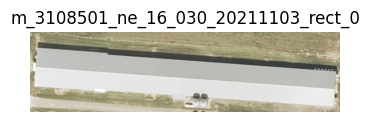

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_0.jpg


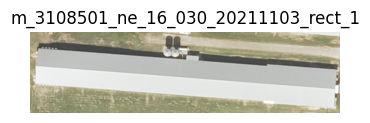

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_1.jpg


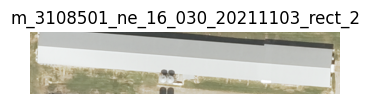

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_2.jpg


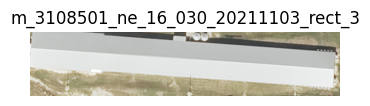

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_3.jpg


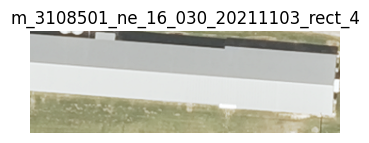

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_4.jpg


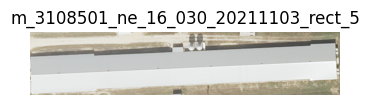

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_5.jpg


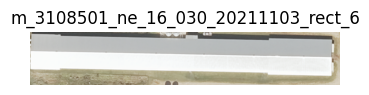

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_6.jpg


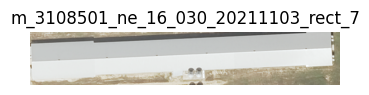

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_7.jpg


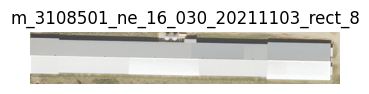

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_8.jpg


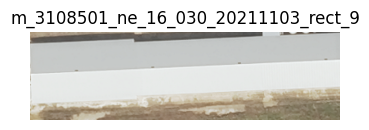

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_9.jpg


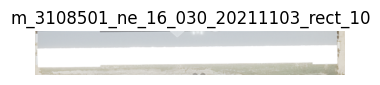

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_10.jpg


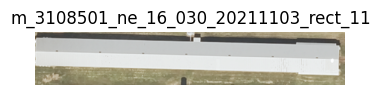

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_11.jpg


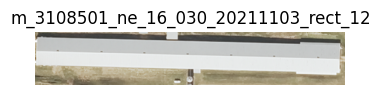

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_12.jpg


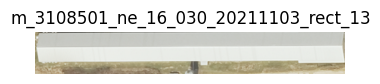

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_13.jpg


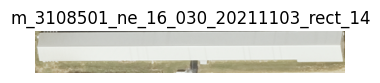

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_14.jpg


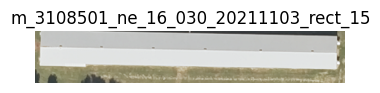

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_15.jpg


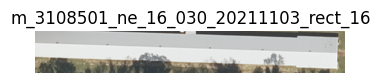

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_16.jpg


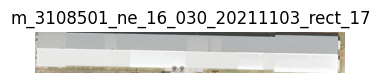

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_17.jpg


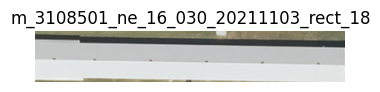

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_18.jpg


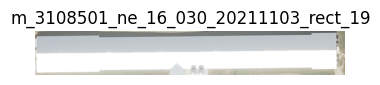

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_19.jpg


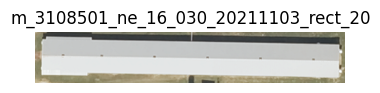

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_20.jpg


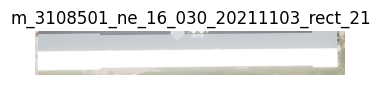

Saved crop: sam_test/cropped_rects\m_3108501_ne_16_030_20211103_rect_21.jpg


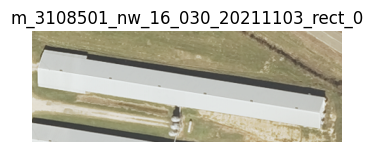

Saved crop: sam_test/cropped_rects\m_3108501_nw_16_030_20211103_rect_0.jpg


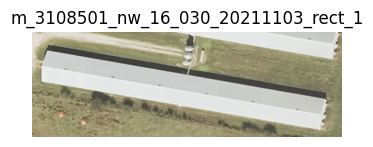

Saved crop: sam_test/cropped_rects\m_3108501_nw_16_030_20211103_rect_1.jpg


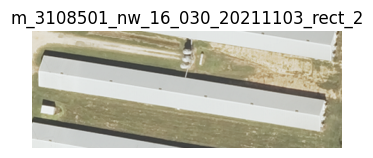

Saved crop: sam_test/cropped_rects\m_3108501_nw_16_030_20211103_rect_2.jpg


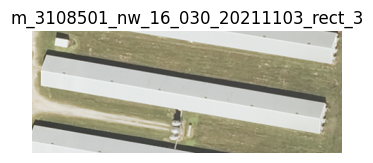

Saved crop: sam_test/cropped_rects\m_3108501_nw_16_030_20211103_rect_3.jpg


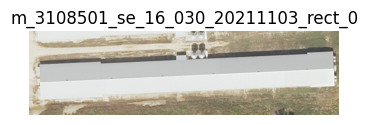

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_0.jpg


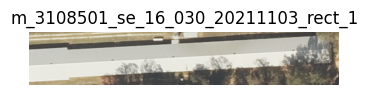

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_1.jpg


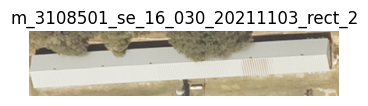

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_2.jpg


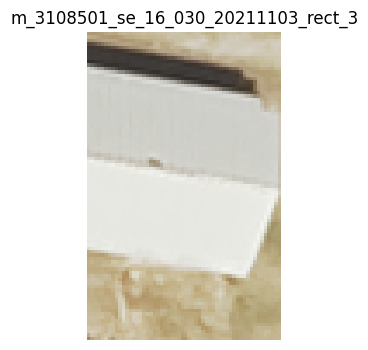

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_3.jpg


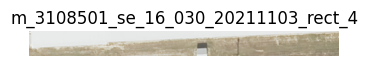

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_4.jpg


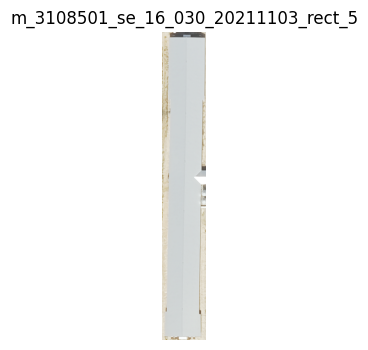

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_5.jpg


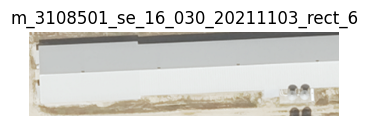

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_6.jpg


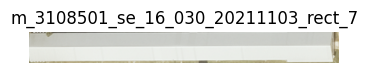

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_7.jpg


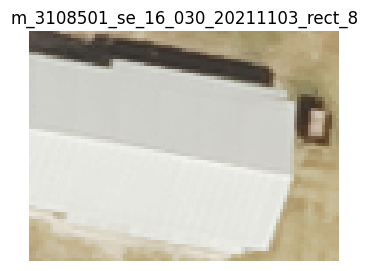

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_8.jpg


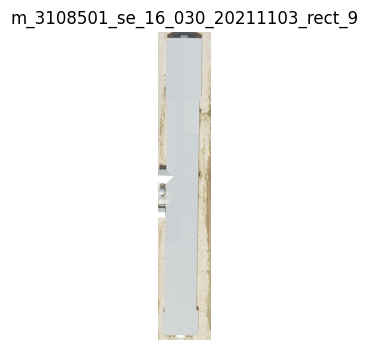

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_9.jpg


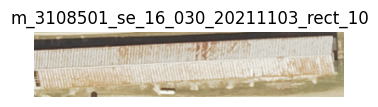

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_10.jpg


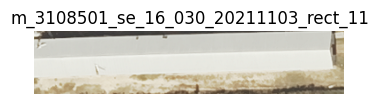

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_11.jpg


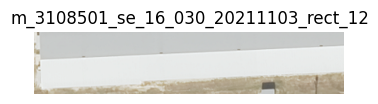

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_12.jpg


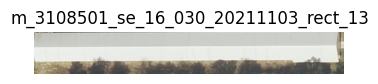

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_13.jpg


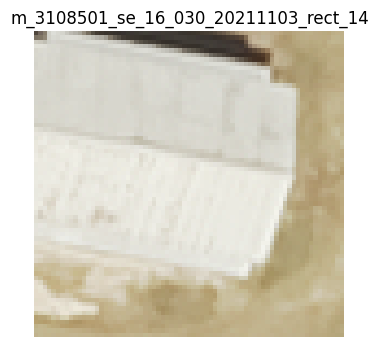

Saved crop: sam_test/cropped_rects\m_3108501_se_16_030_20211103_rect_14.jpg


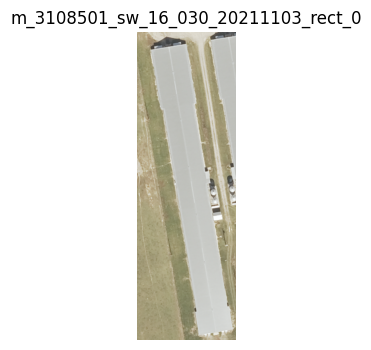

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_0.jpg


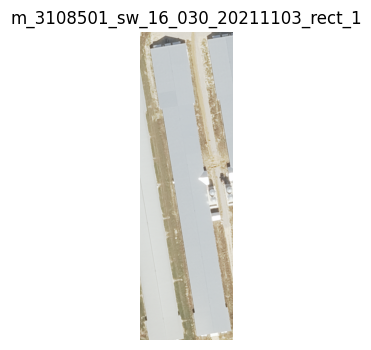

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_1.jpg


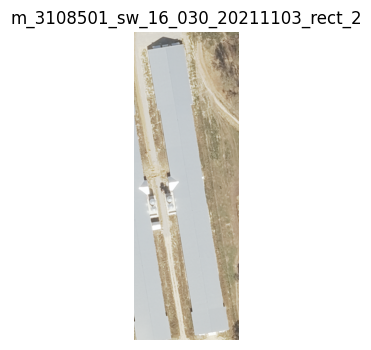

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_2.jpg


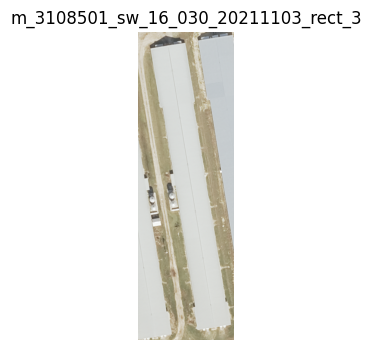

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_3.jpg


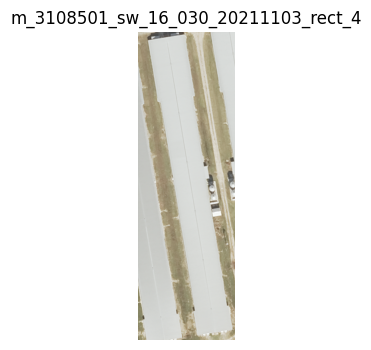

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_4.jpg


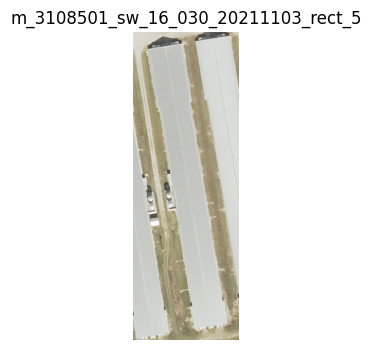

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_5.jpg


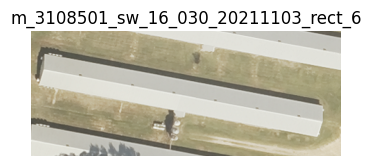

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_6.jpg


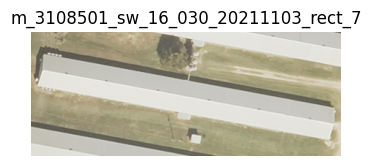

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_7.jpg


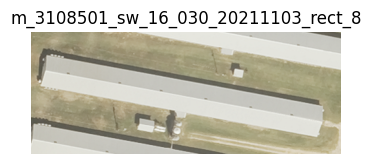

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_8.jpg


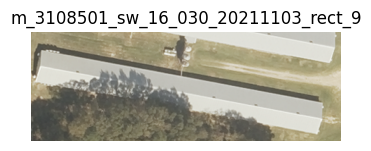

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_9.jpg


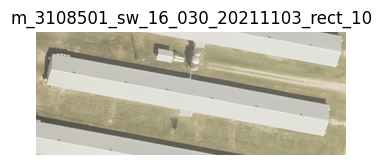

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_10.jpg


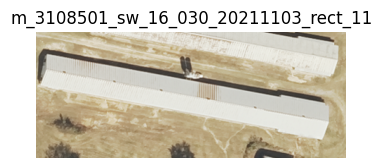

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_11.jpg


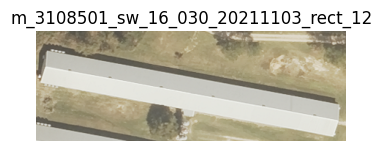

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_12.jpg


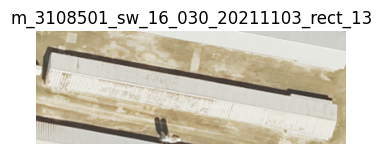

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_13.jpg


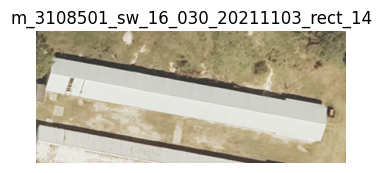

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_14.jpg


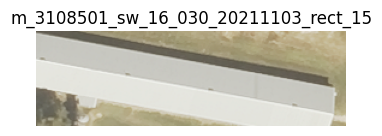

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_15.jpg


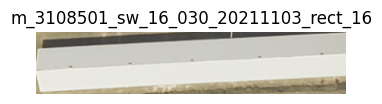

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_16.jpg


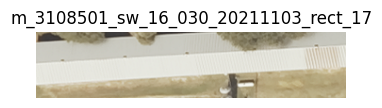

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_17.jpg


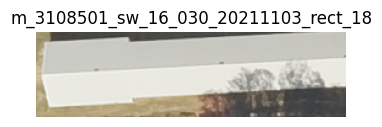

Saved crop: sam_test/cropped_rects\m_3108501_sw_16_030_20211103_rect_18.jpg


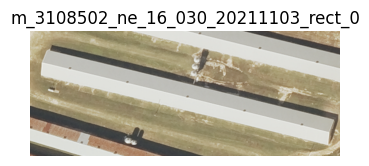

Saved crop: sam_test/cropped_rects\m_3108502_ne_16_030_20211103_rect_0.jpg


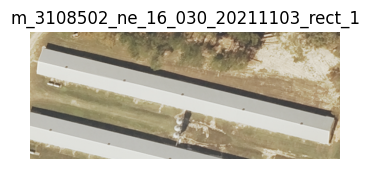

Saved crop: sam_test/cropped_rects\m_3108502_ne_16_030_20211103_rect_1.jpg


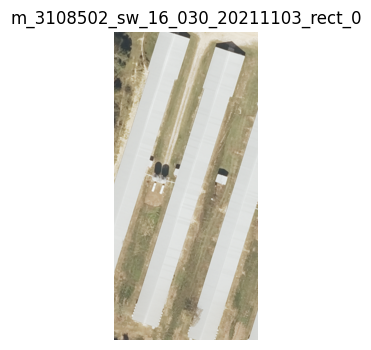

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_0.jpg


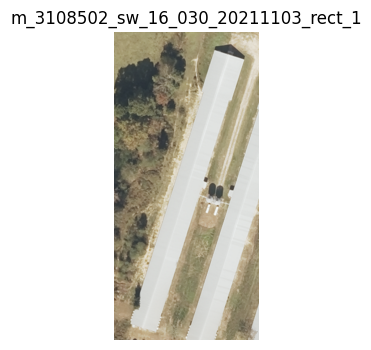

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_1.jpg


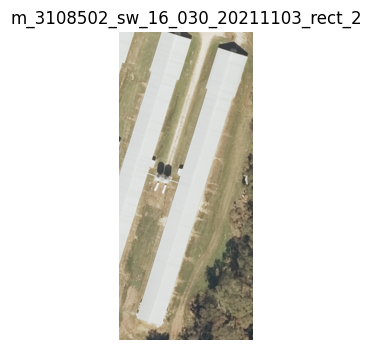

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_2.jpg


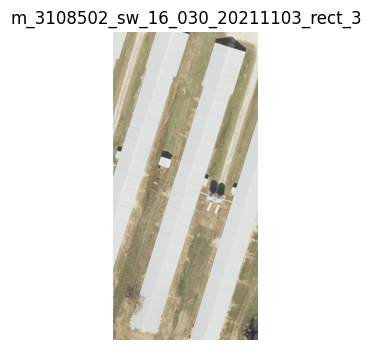

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_3.jpg


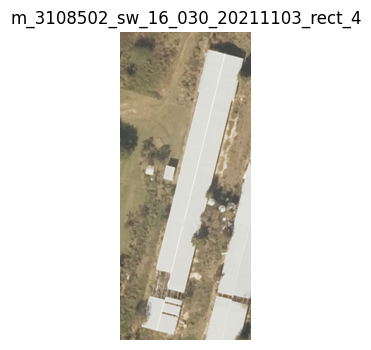

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_4.jpg


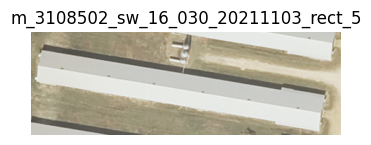

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_5.jpg


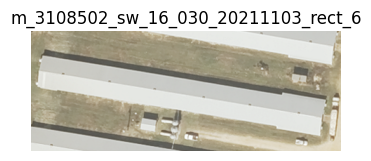

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_6.jpg


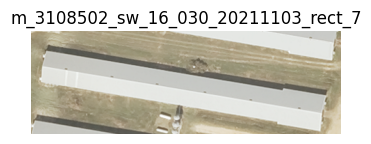

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_7.jpg


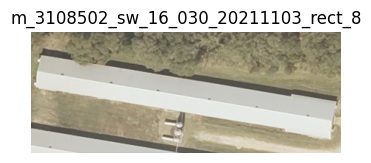

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_8.jpg


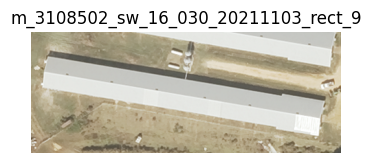

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_9.jpg


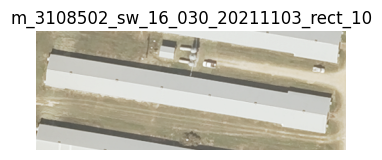

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_10.jpg


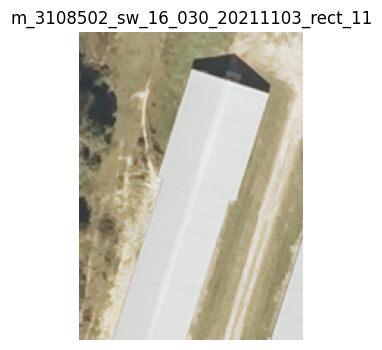

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_11.jpg


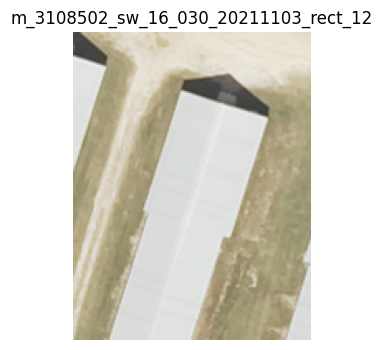

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_12.jpg


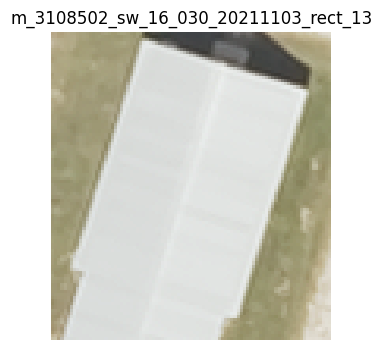

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_13.jpg


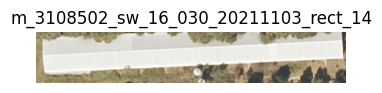

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_14.jpg


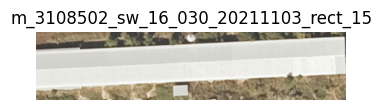

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_15.jpg


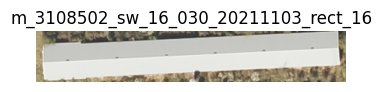

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_16.jpg


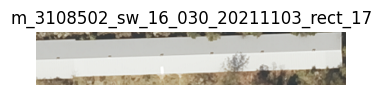

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_17.jpg


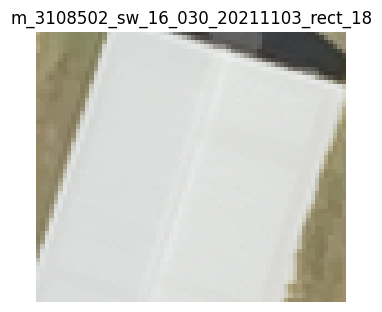

Saved crop: sam_test/cropped_rects\m_3108502_sw_16_030_20211103_rect_18.jpg


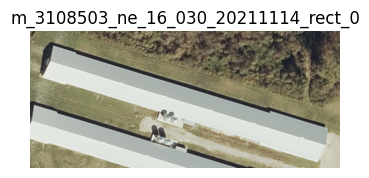

Saved crop: sam_test/cropped_rects\m_3108503_ne_16_030_20211114_rect_0.jpg


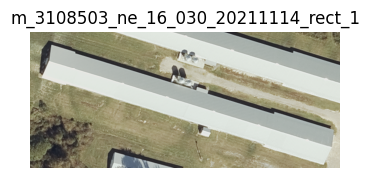

Saved crop: sam_test/cropped_rects\m_3108503_ne_16_030_20211114_rect_1.jpg


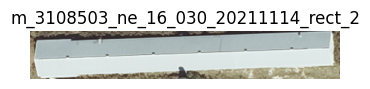

Saved crop: sam_test/cropped_rects\m_3108503_ne_16_030_20211114_rect_2.jpg


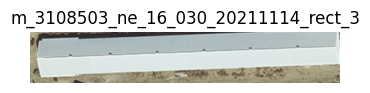

Saved crop: sam_test/cropped_rects\m_3108503_ne_16_030_20211114_rect_3.jpg


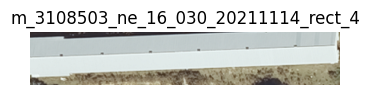

Saved crop: sam_test/cropped_rects\m_3108503_ne_16_030_20211114_rect_4.jpg


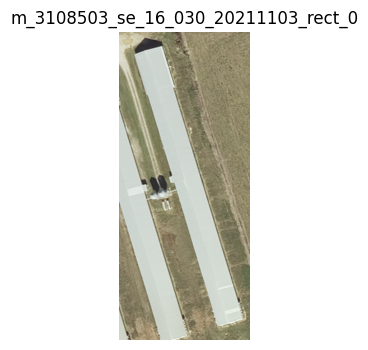

Saved crop: sam_test/cropped_rects\m_3108503_se_16_030_20211103_rect_0.jpg


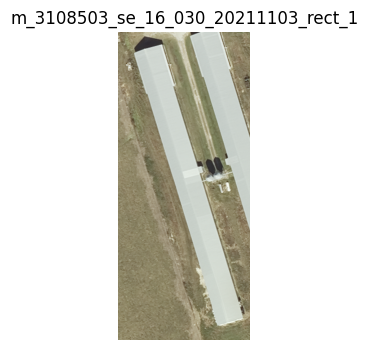

Saved crop: sam_test/cropped_rects\m_3108503_se_16_030_20211103_rect_1.jpg


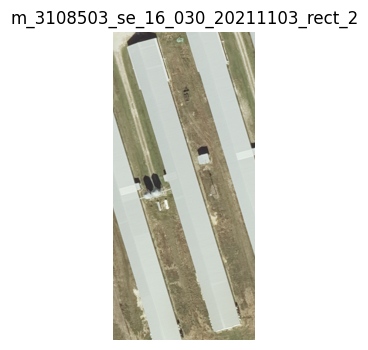

Saved crop: sam_test/cropped_rects\m_3108503_se_16_030_20211103_rect_2.jpg


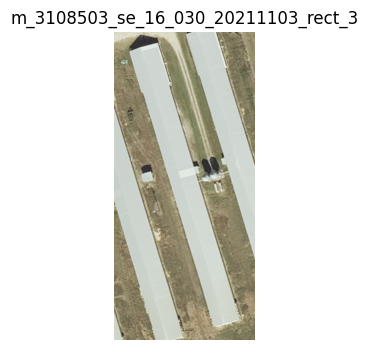

Saved crop: sam_test/cropped_rects\m_3108503_se_16_030_20211103_rect_3.jpg


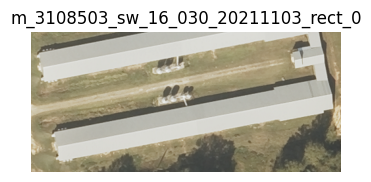

Saved crop: sam_test/cropped_rects\m_3108503_sw_16_030_20211103_rect_0.jpg


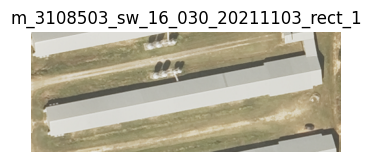

Saved crop: sam_test/cropped_rects\m_3108503_sw_16_030_20211103_rect_1.jpg


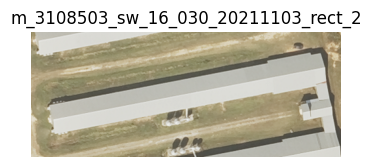

Saved crop: sam_test/cropped_rects\m_3108503_sw_16_030_20211103_rect_2.jpg


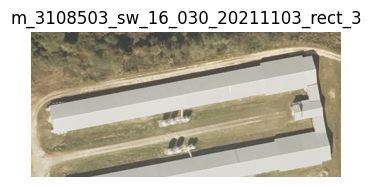

Saved crop: sam_test/cropped_rects\m_3108503_sw_16_030_20211103_rect_3.jpg


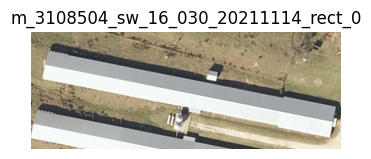

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_0.jpg


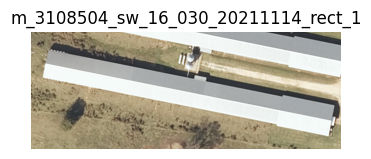

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_1.jpg


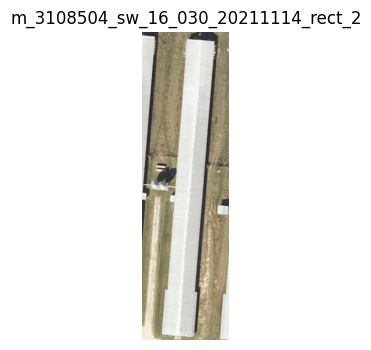

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_2.jpg


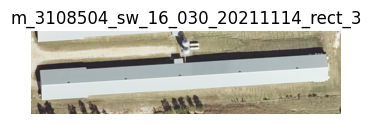

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_3.jpg


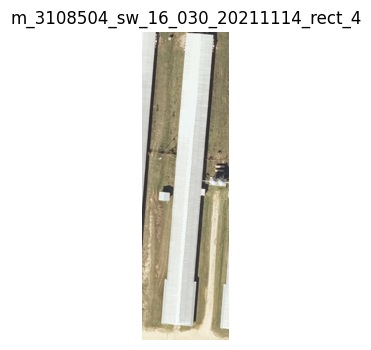

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_4.jpg


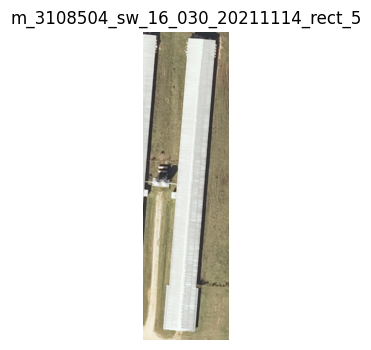

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_5.jpg


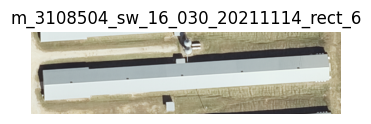

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_6.jpg


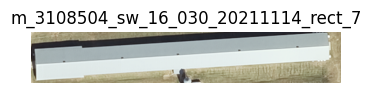

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_7.jpg


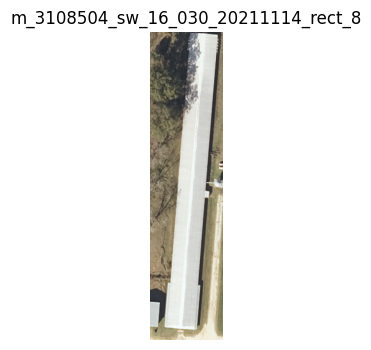

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_8.jpg


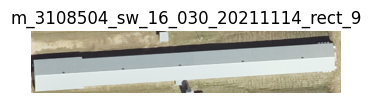

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_9.jpg


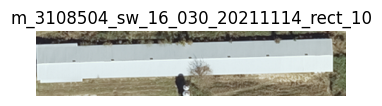

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_10.jpg


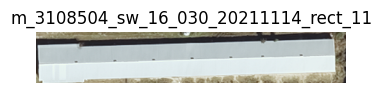

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_11.jpg


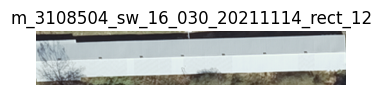

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_12.jpg


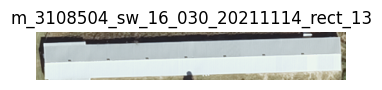

Saved crop: sam_test/cropped_rects\m_3108504_sw_16_030_20211114_rect_13.jpg


In [56]:
import os, glob, ast, numpy as np, pandas as pd, rasterio
from rasterio.transform import rowcol
import matplotlib.pyplot as plt
from PIL import Image

def crop_rectangles(
    full_image_array, full_transform, object_infos, output_dir, image_base
):
    # Prepare image in [H, W, 3] and scale to 0-255
    img = np.moveaxis(full_image_array[:3], 0, -1)
    img = (img / img.max() * 255).astype(np.uint8)

    for idx, obj in enumerate(object_infos):
        try:
            # Convert rectangle GIS points to pixel coordinates
            rect = ast.literal_eval(obj['rect_mask_points'])
            pix = [rowcol(full_transform, X, Y)[::-1] for X, Y in rect]
            pix = np.array(pix, int)

            if pix.shape[0] >= 4:
                # Bounding box for crop
                x0, y0 = pix.min(axis=0)
                x1, y1 = pix.max(axis=0)
                h, w = img.shape[:2]
                x0, y0 = max(x0, 0), max(y0, 0)
                x1, y1 = min(x1, w-1), min(y1, h-1)

                crop = img[y0:y1, x0:x1].copy()
                if crop.size and crop.shape[0] > 0 and crop.shape[1] > 0:
                    # Show with matplotlib
                    plt.figure(figsize=(4,4))
                    plt.imshow(crop)
                    plt.title(f"{image_base}_rect_{idx}")
                    plt.axis('off')
                    plt.show()

                    # Save as JPEG using PIL
                    out_name = f"{image_base}_rect_{idx}.jpg"
                    out_path = os.path.join(output_dir, out_name)
                    Image.fromarray(crop).save(out_path)
                    print(f"Saved crop: {out_path}")
                else:
                    print(f"Empty crop, idx={idx}")
        except Exception as e:
            print(f"Error cropping idx={idx}: {e}")

def run_cropper(folder, csv_sup, out_dir):
    df = pd.read_csv(csv_sup)
    df['base'] = df['tile_name'].str.split('.tif').str[0]
    tifs = glob.glob(os.path.join(folder, '**', '*.tif'), recursive=True)
    os.makedirs(out_dir, exist_ok=True)

    for tif in tifs:
        with rasterio.open(tif) as src:
            arr = src.read(); tfm = src.transform
        name = os.path.splitext(os.path.basename(tif))[0]
        objs = df[df['base']==name].to_dict('records')
        crop_rectangles(arr, tfm, objs, out_dir, name)

# Example usage:
run_cropper(
    folder="C:/Users/mza0288/Documents/Code/test_sample",
    csv_sup="sam_test/final_rect_highest_conf.csv",
    out_dir="sam_test/cropped_rects"
)
